# Serie di potenze, Frobenius, perturbazione

### Subject: Algebra and calculus (Carillo)

Il modulo non è «gate Pauli»: è **ODE**. Tre fatti che si possono
*eseguire*, non solo scrivere:

1. la serie di potenze in un punto ordinario ricostruisce $\sin$ e $\cos$;
2. Frobenius su un punto singolare regolare (Bessel $J_0$) dà la stessa
   ricorrenza del libro, e la serie coincide con `scipy.special.j0`;
3. la perturbazione *naive* dell'oscillatore debolmente smorzato produce
   un termine secolare $t\cos t$ — il segnale che il metodo è sbagliato —
   mentre la soluzione esatta decade.

Le esercitazioni del corso restano in `data/` (gitignored).


## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

def rk4(f, y0, t):
    y = np.empty((len(t),) + np.shape(y0), dtype=np.asarray(y0).dtype)
    y[0] = y0
    for i in range(len(t) - 1):
        h = t[i + 1] - t[i]
        k1 = f(t[i], y[i])
        k2 = f(t[i] + 0.5 * h, y[i] + 0.5 * h * k1)
        k3 = f(t[i] + 0.5 * h, y[i] + 0.5 * h * k2)
        k4 = f(t[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    return y

print("Setup ready.")


Setup ready.


## 1. Punto ordinario: $y''+y=0$

Ansatz $y=\sum_{n=0}^N a_n x^n$. Sostituendo:

$$
a_{n+2}=-\frac{a_n}{(n+1)(n+2)}.
$$

Con $(a_0,a_1)=(1,0)$ si ottiene $\cos x$; con $(0,1)$ si ottiene $\sin x$.
Se la ricorrenza è giusta, il troncamento deve coincidere con NumPy
finché $N$ è abbastanza grande e $x$ non è troppo lontano dall'origine.


max |series-cos| on [-8,8] = 8.07e-14
max |series-sin| on [-8,8] = 2.75e-13


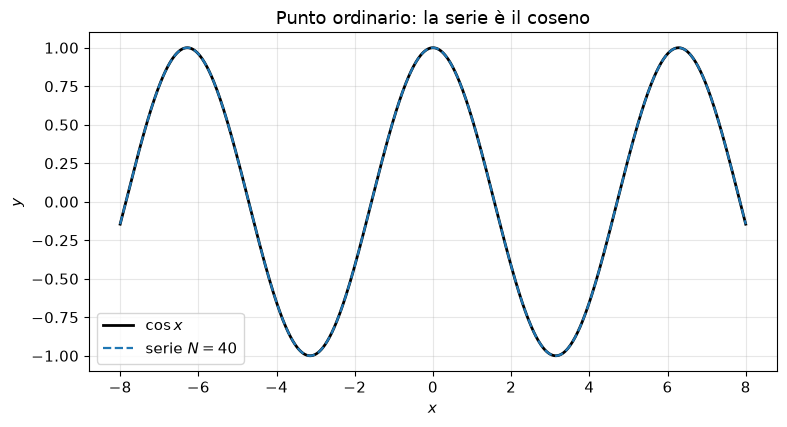

In [2]:
def power_series_oscillator(a0, a1, N, x):
    a = np.zeros(N + 1, dtype=float)
    a[0], a[1] = a0, a1
    for n in range(N - 1):
        a[n + 2] = -a[n] / ((n + 1) * (n + 2))
    y = np.zeros_like(x, dtype=float)
    xn = np.ones_like(x)
    for n, coeff in enumerate(a):
        y = y + coeff * xn
        xn = xn * x
    return y, a


x = np.linspace(-8.0, 8.0, 801)
y_cos, a_cos = power_series_oscillator(1.0, 0.0, N=40, x=x)
y_sin, a_sin = power_series_oscillator(0.0, 1.0, N=40, x=x)

err_cos = np.max(np.abs(y_cos - np.cos(x)))
err_sin = np.max(np.abs(y_sin - np.sin(x)))
print(f"max |series-cos| on [-8,8] = {err_cos:.2e}")
print(f"max |series-sin| on [-8,8] = {err_sin:.2e}")
assert err_cos < 1e-10 and err_sin < 1e-10

fig, ax = plt.subplots()
ax.plot(x, np.cos(x), "k", lw=2, label=r"$\cos x$")
ax.plot(x, y_cos, "--", lw=1.6, label="serie $N=40$")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.legend()
ax.set_title("Punto ordinario: la serie è il coseno")
plt.tight_layout()
plt.show()


## 2. Frobenius: Bessel $J_0$

$x=0$ è singolare regolare per

$$
x^2 y''+x y'+x^2 y=0
\qquad\Leftrightarrow\qquad
xy''+y'+x y=0.
$$

Indice $r=0$ (doppio). La ricorrenza pari è $a_n=-a_{n-2}/n^2$,
$a_0=1$, $a_{\mathrm{odd}}=0$:

$$
J_0(x)=\sum_{k=0}^\infty\frac{(-1)^k}{(k!)^2}\Bigl(\frac{x}{2}\Bigr)^{2k}.
$$

Confrontiamo il troncamento con `j0` di SciPy: stesso oggetto, due strade.


max |Frobenius-j0| on [0,20] = 8.16e-10
primi zeri (cambio segno della serie): [2.425 5.525 8.675]


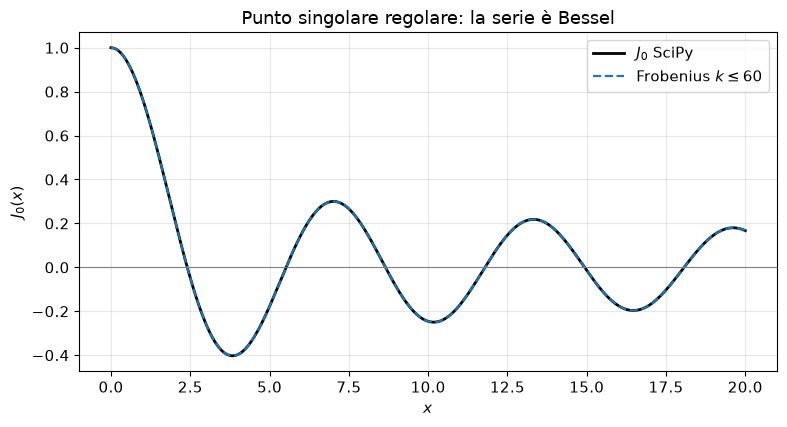

In [3]:
from scipy.special import j0


def frobenius_j0(x, kmax=40):
    y = np.ones_like(x, dtype=float)
    term = np.ones_like(x, dtype=float)
    for k in range(1, kmax + 1):
        term = term * (-(x * x) / (4.0 * k * k))
        y = y + term
    return y


x = np.linspace(0.0, 20.0, 801)
y_series = frobenius_j0(x, kmax=60)
y_lib = j0(x)
err = np.max(np.abs(y_series - y_lib))
print(f"max |Frobenius-j0| on [0,20] = {err:.2e}")
assert err < 1e-8

zeros_est = x[1:][(y_series[1:] * y_series[:-1]) < 0]
print("primi zeri (cambio segno della serie):", np.round(zeros_est[:3], 4))

fig, ax = plt.subplots()
ax.plot(x, y_lib, "k", lw=2, label=r"$J_0$ SciPy")
ax.plot(x, y_series, "--", lw=1.6, label="Frobenius $k\\leq 60$")
ax.axhline(0.0, color="0.5", lw=0.8)
ax.set_xlabel("$x$")
ax.set_ylabel(r"$J_0(x)$")
ax.legend()
ax.set_title("Punto singolare regolare: la serie è Bessel")
plt.tight_layout()
plt.show()


## 3. Perché la perturbazione naive fallisce

Oscillatore debolmente smorzato ($\varepsilon\ll 1$):

$$
\ddot y+2\varepsilon\dot y+y=0,\qquad y(0)=1,\ \dot y(0)=0.
$$

Soluzione esatta: $y(t)=e^{-\varepsilon t}\bigl(\cos\omega t
+(\varepsilon/\omega)\sin\omega t\bigr)$, $\omega=\sqrt{1-\varepsilon^2}$.

Ansatz naive $y=y_0+\varepsilon y_1+\cdots$. All'ordine 0 si ha
$y_0=\cos t$. All'ordine 1:

$$
\ddot y_1+y_1=-2\dot y_0=2\sin t.
$$

Il secondo membro è una **risonanza**: compare un particolare
$-t\cos t$. Su tempi $t\sim 1/\varepsilon$ il termine $\varepsilon t$
non è piccolo — la serie è secolare, non asintotica.

La figura confronta esatto, naive e integrazione RK4. Il messaggio
è numerico: se la tua «correzione» cresce, hai sbagliato scala, non
coefficiente.


RK4 vs exact (max abs) = 6.12e-09


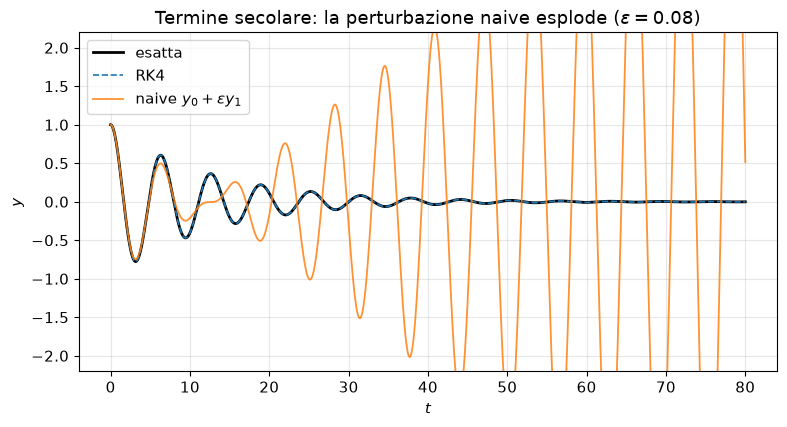

In [4]:
eps = 0.08
t = np.linspace(0.0, 80.0, 4001)
omega = np.sqrt(1.0 - eps * eps)
y_exact = np.exp(-eps * t) * (np.cos(omega * t) + (eps / omega) * np.sin(omega * t))

# naive: y0 + eps y1, y1 particular = -t cos t, plus homogeneous to match IC
# y(0)=1, y'(0)=0 already satisfied by y0=cos t if y1(0)=y1'(0)=0
# y1 = -t cos t  has y1(0)=0, y1'(0)=-1 → add sin t: y1 = -t cos t + sin t
y_naive = np.cos(t) + eps * (-t * np.cos(t) + np.sin(t))


def f_damped(ti, u):
    y, v = u
    return np.array([v, -2.0 * eps * v - y])


u_num = rk4(f_damped, np.array([1.0, 0.0]), t)[:, 0]
err_rk = np.max(np.abs(u_num - y_exact))
print(f"RK4 vs exact (max abs) = {err_rk:.2e}")
assert err_rk < 2e-4

fig, ax = plt.subplots()
ax.plot(t, y_exact, "k", lw=2, label="esatta")
ax.plot(t, u_num, "--", lw=1.2, label="RK4")
ax.plot(t, y_naive, lw=1.3, alpha=0.85, label=r"naive $y_0+\varepsilon y_1$")
ax.set_xlabel("$t$")
ax.set_ylabel("$y$")
ax.set_ylim(-2.2, 2.2)
ax.legend()
ax.set_title(r"Termine secolare: la perturbazione naive esplode ($\varepsilon=0.08$)")
plt.tight_layout()
plt.show()


## Takeaway

- Punto **ordinario** → Taylor, ricorrenza a due passi, $\sin/\cos$.
- Punto **singolare regolare** → Frobenius, Bessel.
- Perturbazione **diretta** su un oscillatore risonante → termini
  secolari. Serve un altro metodo (scale multiple, Poincaré–Lindstedt),
  non più termini della stessa serie.

## Next step
- Poincaré–Lindstedt: allungare il tempo $\tau=\omega(\varepsilon)t$
  e uccidere i secolari ordine per ordine.
- Hermite come secondo esempio di Frobenius (oscillatore quantistico).
